[Dark] Loaded: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug\Portable_Raman_database\dark_di_water.txt
[Dark] Raw points: 2048, after trim: 2018


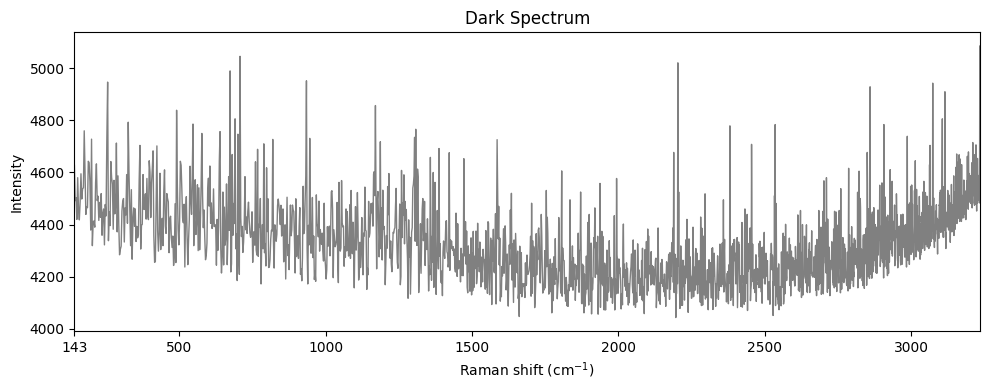

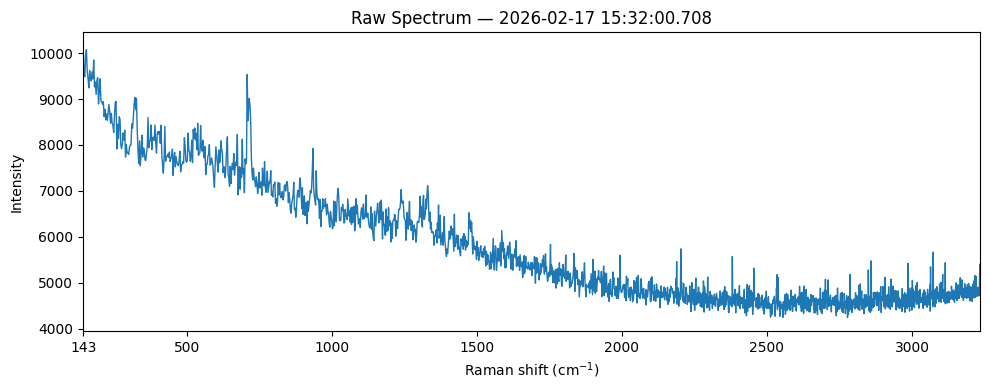

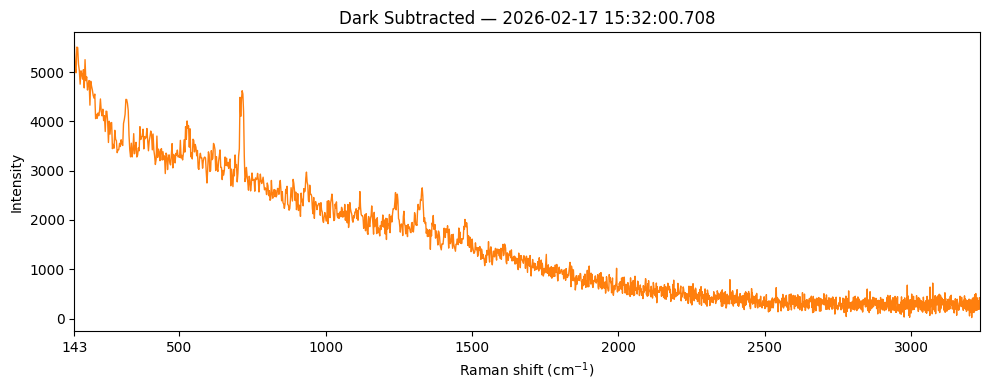

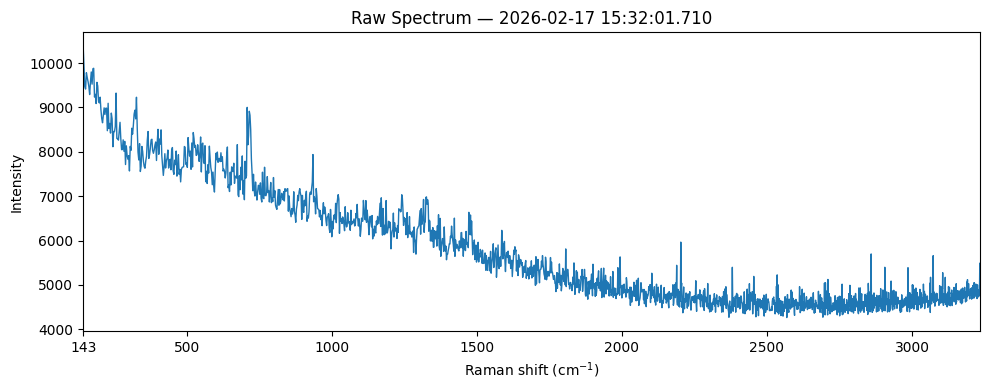

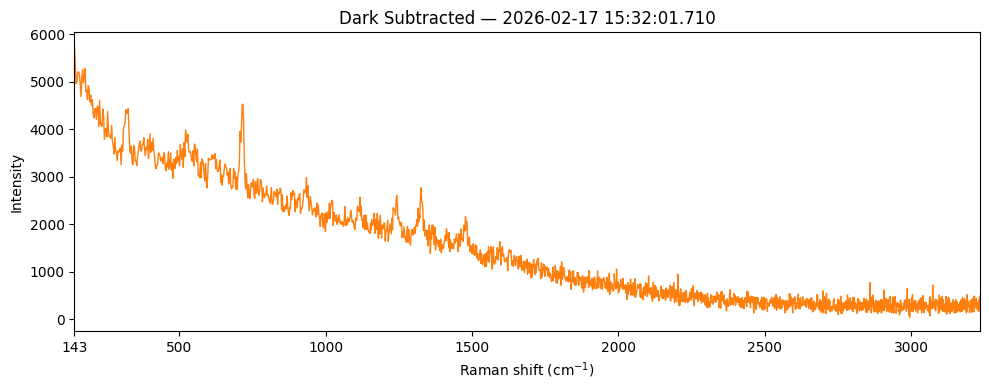

...

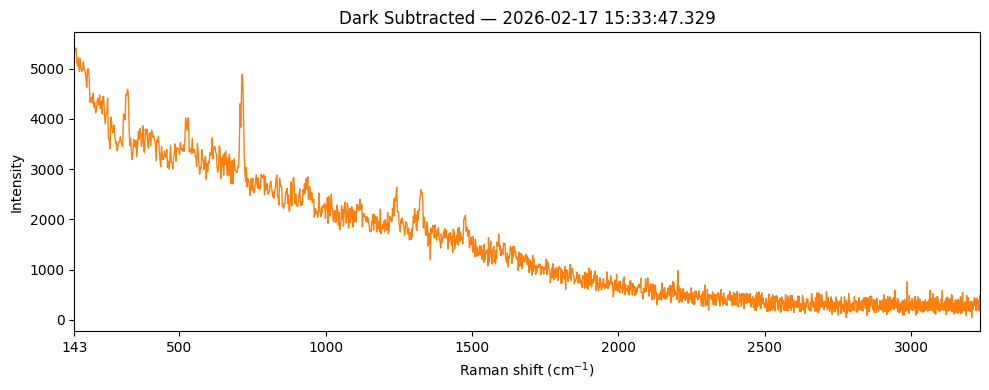

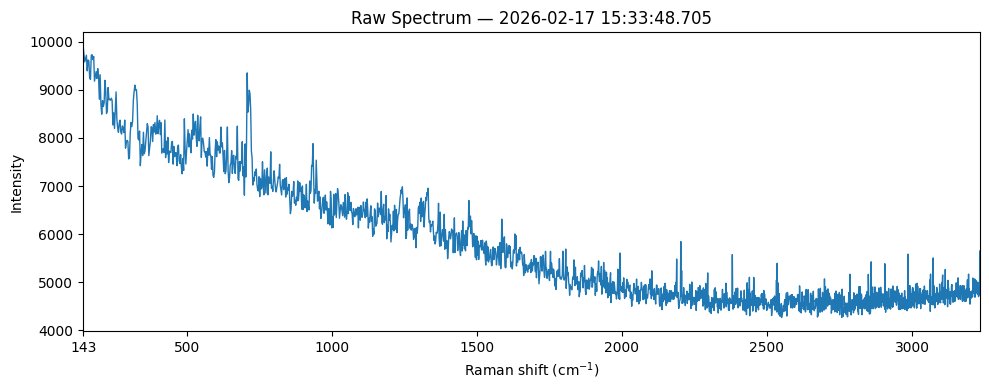

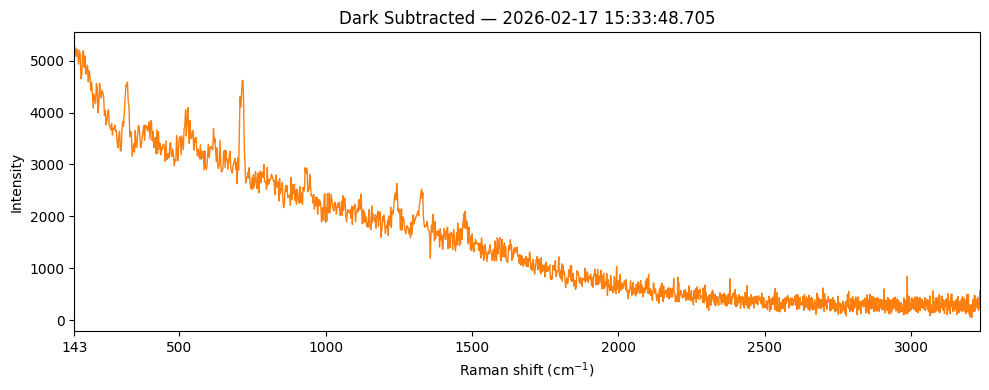

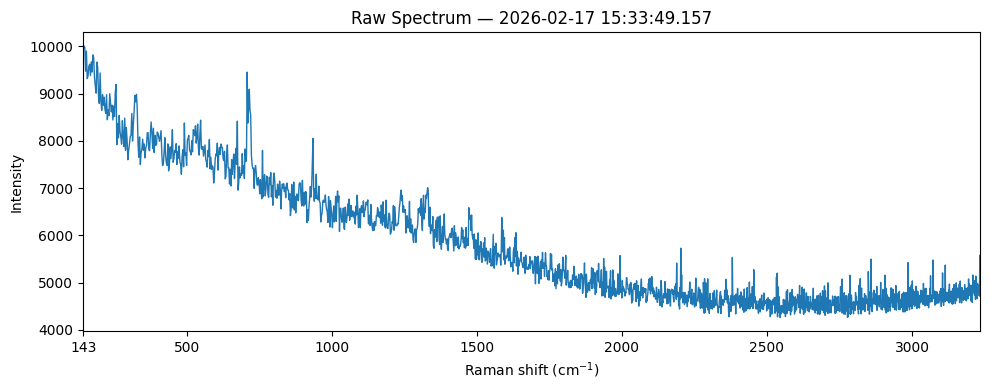

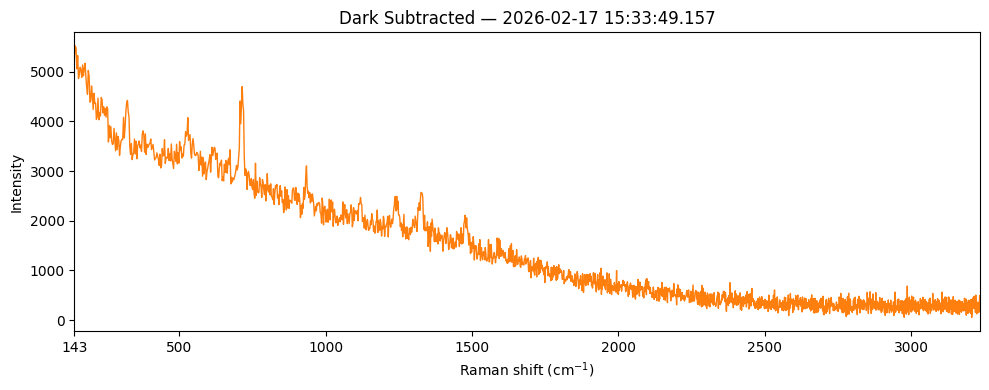

In [ ]:
# --- Portable data location (added by macos-native/tools/mac_python_paths.py) ---------------------
# RAMAN_HANDOFF_DIR is the hand-off folder laser_test/build/Desktop_Qt_6_6_3_MSVC2019_64bit-Debug,
# found by walking up from this file (a notebook: from its working folder). To use another copy,
# set the RAMAN_HANDOFF_DIR environment variable to that folder.
import os as _os


def _raman_handoff_dir():
    if _os.environ.get("RAMAN_HANDOFF_DIR"):
        return _os.path.abspath(_os.environ["RAMAN_HANDOFF_DIR"])
    start = _os.path.dirname(_os.path.abspath(globals()["__file__"])) if "__file__" in globals() else _os.getcwd()
    folder = start
    while True:
        candidate = _os.path.join(folder, "laser_test", "build", "Desktop_Qt_6_6_3_MSVC2019_64bit-Debug")
        if _os.path.isdir(candidate):
            return candidate
        parent = _os.path.dirname(folder)
        if parent == folder:
            raise FileNotFoundError("laser_test/build/Desktop_Qt_6_6_3_MSVC2019_64bit-Debug not found above "
                                    + start + "; set the RAMAN_HANDOFF_DIR environment variable")
        folder = parent


RAMAN_HANDOFF_DIR = _raman_handoff_dir()
# ---------------------------------------------------------------------------------------------------
from pathlib import Path
from datetime import datetime
import re
import glob
import numpy as np
import matplotlib.pyplot as plt

LOG_PATH = f"{RAMAN_HANDOFF_DIR}/Portable_Raman_database/Database_adenine.txt"

# Specify the dark file path directly
DARK_PATH = f"{RAMAN_HANDOFF_DIR}/Portable_Raman_database/dark_adenine.txt"

TS_RE = re.compile(r"\[?(\d{4}-\d{2}-\d{2})[ T](\d{2}:\d{2}:\d{2})(?:\.(\d{1,3}))?\]?")
HEX_TOKEN_RE = re.compile(r"(?:0x)?[0-9A-Fa-f]{2,8}")
ERROR_PHRASE = "image data error code 0x0001"

RAMAN_SHIFT_2048 = np.array([
    57.42448267, 60.29131328, 63.15612404, 66.01891664, 68.87969276, 71.73845411, 74.59520236, 77.44993921, 80.30266633, 83.15338541,
    86.00209813, 88.84880617, 91.6935112, 94.53621489, 97.37691893, 100.215625, 103.0523347, 105.8870498, 108.7197719, 111.5505026,
    114.3792437, 117.2059968, 120.0307636, 122.8535457, 125.6743447, 128.4931623, 131.3100002, 134.1248601, 136.9377435, 139.7486521,
    142.5575875, 145.3645515, 148.1695455, 150.9725714, 153.7736306, 156.5727249, 159.3698559, 162.1650252, 164.9582344, 167.7494851,
    170.5387791, 173.3261178, 176.111503, 178.8949363, 181.6764192, 184.4559533, 187.2335404, 190.009182, 192.7828797, 195.5546352,
    198.32445, 201.0923257, 203.8582639, 206.6222664, 209.3843345, 212.1444701, 214.9026745, 217.6589495, 220.4132966, 223.1657175,
    225.9162137, 228.6647868, 231.4114383, 234.15617, 236.8989832, 239.6398798, 242.3788611, 245.1159289, 247.8510846, 250.5843298,
    253.3156662, 256.0450953, 258.7726186, 261.4982377, 264.2219542, 266.9437697, 269.6636857, 272.3817038, 275.0978255, 277.8120524,
    280.524386, 283.234828, 285.9433797, 288.6500429, 291.3548191, 294.0577097, 296.7587164, 299.4578407, 302.1550841, 304.8504482,
    307.5439344, 310.2355445, 312.9252798, 315.6131419, 318.2991323, 320.9832527, 323.6655044, 326.3458891, 329.0244082, 331.7010633,
    334.3758559, 337.0487875, 339.7198596, 342.3890738, 345.0564316, 347.7219345, 350.3855839, 353.0473815, 355.7073287, 358.365427,
    361.0216779, 363.676083, 366.3286437, 368.9793615, 371.6282379, 374.2752745, 376.9204727, 379.5638341, 382.20536, 384.8450521,
    387.4829117, 390.1189404, 392.7531397, 395.385511, 398.0160559, 400.6447758, 403.2716721, 405.8967465, 408.5200003, 411.141435,
    413.7610521, 416.3788531, 418.9948394, 421.6090125, 424.2213739, 426.831925, 429.4406673, 432.0476023, 434.6527314,
    437.2560561, 439.8575778, 442.4572981, 445.0552182, 447.6513398, 450.2456643, 452.838193, 455.4289275, 458.0178692, 460.6050195,
    463.1903799, 465.7739518, 468.3557368, 470.9357361, 473.5139512, 476.0903837, 478.6650348, 481.2379061, 483.808999, 486.3783149,
    488.9458552, 491.5116214, 494.0756149, 496.637837, 499.1982893, 501.7569732, 504.31389, 506.8690412, 509.4224283, 511.9740525,
    514.5239154, 517.0720183, 519.6183627, 522.1629499, 524.7057814, 527.2468585, 529.7861828, 532.3237555, 534.8595781, 537.3936519,
    539.9259785, 542.4565591, 544.9853952, 547.5124881, 550.0378393, 552.5614502, 555.0833221, 557.6034563, 560.1218544, 562.6385177,
    565.1534476, 567.6666454, 570.1781125, 572.6878504, 575.1958603, 577.7021437, 580.206702, 582.7095365, 585.2106485, 587.7100395,
    590.2077108, 592.7036638, 595.1978999, 597.6904204, 600.1812266, 602.67032, 605.1577019, 607.6433737, 610.1273367, 612.6095922,
    615.0901417, 617.5689865, 620.0461278, 622.5215672, 624.9953059, 627.4673453, 629.9376867, 632.4063314, 634.8732809, 637.3385364,
    639.8020993, 642.2639709, 644.7241525, 647.1826456, 649.6394514, 652.0945713, 654.5480066, 656.9997586, 659.4498286, 661.8982181,
    664.3449282, 666.7899604, 669.2333159, 671.6749961, 674.1150023, 676.5533358, 678.9899979, 681.42499, 683.8583134, 686.2899693,
    688.7199592, 691.1482842, 693.5749457, 695.999945, 698.4232835, 700.8449624, 703.264983, 705.6833467, 708.1000547, 710.5151083,
    712.9285088, 715.3402576, 717.7503559, 720.158805, 722.5656063, 724.9707609, 727.3742702, 729.7761355, 732.1763581, 734.5749392,
    736.9718802, 739.3671822, 741.7608467, 744.1528749, 746.543268, 748.9320274, 751.3191543, 753.70465, 756.0885158, 758.4707529,
    760.8513626, 763.2303462, 765.6077049, 767.98344, 770.3575529, 772.7300447, 775.1009167, 777.4701702, 779.8378064, 782.2038266,
    784.568232, 786.931024, 789.2922037, 791.6517725, 794.0097315, 796.366082, 798.7208253, 801.0739627, 803.4254953, 805.7754244,
    808.1237513, 810.4704772, 812.8156033, 815.159131, 817.5010613, 819.8413957, 822.1801352, 824.5172812, 826.8528349, 829.1867974,
    831.5191702, 833.8499542, 836.1791509, 838.5067615, 840.832787, 843.1572289, 845.4800883, 847.8013664, 850.1210645, 852.4391837,
    854.7557254, 857.0706907, 859.3840808, 861.6958969, 864.0061403, 866.3148122, 868.6219138, 870.9274462, 873.2314108, 875.5338087,
    877.8346411, 880.1339093, 882.4316144, 884.7277576, 887.0223402, 889.3153633, 891.6068282, 893.896736, 896.1850879, 898.4718852,
    900.757129, 903.0408205, 905.3229609, 907.6035515, 909.8825933, 912.1600876, 914.4360356, 916.7104385, 918.9832974, 921.2546135,
    923.524388, 925.7926222, 928.059317, 930.3244739, 932.5880939, 934.8501782, 937.1107279, 939.3697443, 941.6272286, 943.8831818,
    946.1376052, 948.3905, 950.6418672, 952.8917082, 955.1400239, 957.3868157, 959.6320847, 961.875832, 964.1180587, 966.3587662,
    968.5979554, 970.8356276, 973.0717839, 975.3064255, 977.5395536, 979.7711692, 982.0012736, 984.2298678, 986.4569531, 988.6825306,
    990.9066014, 993.1291667, 995.3502276, 997.5697853, 999.7878409, 1002.004396, 1004.21945, 1006.433007, 1008.645065, 1010.855627,
    1013.064694, 1015.272267, 1017.478347, 1019.682935, 1021.886032, 1024.08764, 1026.287759, 1028.486391, 1030.683537, 1032.879197,
    1035.073374, 1037.266068, 1039.45728, 1041.647011, 1043.835263, 1046.022036, 1048.207333, 1050.391153, 1052.573498, 1054.754369,
    1056.933768, 1059.111694, 1061.288151, 1063.463137, 1065.636656, 1067.808707, 1069.979292, 1072.148412, 1074.316068, 1076.482261,
    1078.646992, 1080.810263, 1082.972075, 1085.132427, 1087.291323, 1089.448762, 1091.604746, 1093.759277, 1095.912354, 1098.063979,
    1100.214154, 1102.362878, 1104.510155, 1106.655983, 1108.800366, 1110.943303, 1113.084796, 1115.224845, 1117.363453, 1119.500619,
    1121.636346, 1123.770633, 1125.903483, 1128.034896, 1130.164874, 1132.293417, 1134.420527, 1136.546204, 1138.67045, 1140.793265,
    1142.914652, 1145.03461, 1147.153141, 1149.270246, 1151.385927, 1153.500183, 1155.613017, 1157.724429, 1159.83442, 1161.942992,
    1164.050145, 1166.15588, 1168.260199, 1170.363103, 1172.464592, 1174.564668, 1176.663332, 1178.760585, 1180.856427, 1182.950861,
    1185.043886, 1187.135505, 1189.225717, 1191.314525, 1193.401928, 1195.487929, 1197.572528, 1199.655727, 1201.737526, 1203.817926,
    1205.896928, 1207.974534, 1210.050744, 1212.12556, 1214.198982, 1216.271012, 1218.341651, 1220.410899, 1222.478758, 1224.545228,
    1226.610311, 1228.674008, 1230.736319, 1232.797247, 1234.856791, 1236.914953, 1238.971734, 1241.027134, 1243.081156, 1245.1338,
    1247.185066, 1249.234956, 1251.283471, 1253.330613, 1255.376381, 1257.420777, 1259.463802, 1261.505458, 1263.545744, 1265.584662,
    1267.622213, 1269.658399, 1271.693219, 1273.726675, 1275.758769, 1277.7895, 1279.818871, 1281.846881, 1283.873533, 1285.898827,
    1287.922764, 1289.945344, 1291.96657, 1293.986442, 1296.004961, 1298.022128, 1300.037944, 1302.05241, 1304.065527, 1306.077296,
    1308.087718, 1310.096794, 1312.104524, 1314.110911, 1316.115955, 1318.119656, 1320.122017, 1322.123037, 1324.122718, 1326.121061,
    1328.118067, 1330.113736, 1332.10807, 1334.10107, 1336.092737, 1338.083071, 1340.072074, 1342.059746, 1344.046089, 1346.031104,
    1348.014791, 1349.997152, 1351.978187, 1353.957897, 1355.936284, 1357.913348, 1359.889091, 1361.863513, 1363.836615, 1365.808398,
    1367.778863, 1369.748012, 1371.715844, 1373.682362, 1375.647565, 1377.611456, 1379.574034, 1381.535301, 1383.495258, 1385.453906,
    1387.411245, 1389.367277, 1391.322003, 1393.275423, 1395.227538, 1397.17835, 1399.12786, 1401.076067, 1403.022974, 1404.968581,
    1406.912889, 1408.8559, 1410.797613, 1412.73803, 1414.677153, 1416.61498, 1418.551515, 1420.486758, 1422.420709, 1424.353369,
    1426.28474, 1428.214823, 1430.143618, 1432.071126, 1433.997348, 1435.922286, 1437.845939, 1439.76831, 1441.689398, 1443.609205,
    1445.527732, 1447.44498, 1449.360949, 1451.275641, 1453.189056, 1455.101196, 1457.012061, 1458.921652, 1460.82997, 1462.737016,
    1464.642791, 1466.547296, 1468.450531, 1470.352499, 1472.253199, 1474.152632, 1476.0508, 1477.947703, 1479.843342, 1481.737719,
    1483.630833, 1485.522686, 1487.413279, 1489.302613, 1491.190689, 1493.077507, 1494.963068, 1496.847374, 1498.730425, 1500.612222,
    1502.492767, 1504.372059, 1506.250099, 1508.12689, 1510.002431, 1511.876724, 1513.749769, 1515.621567, 1517.49212, 1519.361427,
    1521.229491, 1523.096311, 1524.961889, 1526.826226, 1528.689322, 1530.551178, 1532.411796, 1534.271176, 1536.129319, 1537.986225,
    1539.841897, 1541.696334, 1543.549538, 1545.401509, 1547.252248, 1549.101756, 1550.950035, 1552.797084, 1554.642905, 1556.487499,
    1558.330867, 1560.173008, 1562.013925, 1563.853618, 1565.692088, 1567.529336, 1569.365363, 1571.200169, 1573.033756, 1574.866124,
    1576.697274, 1578.527207, 1580.355925, 1582.183427, 1584.009714, 1585.834788, 1587.658649, 1589.481299, 1591.302738, 1593.122966,
    1594.941985, 1596.759796, 1598.5764, 1600.391796, 1602.205987, 1604.018973, 1605.830755, 1607.641333, 1609.450709, 1611.258884,
    1613.065858, 1614.871632, 1616.676206, 1618.479583, 1620.281762, 1622.082745, 1623.882532, 1625.681124, 1627.478523, 1629.274728,
    1631.06974, 1632.863562, 1634.656192, 1636.447633, 1638.237885, 1640.026949, 1641.814826, 1643.601516, 1645.38702, 1647.17134,
    1648.954475, 1650.736428, 1652.517198, 1654.296787, 1656.075195, 1657.852423, 1659.628472, 1661.403343, 1663.177037, 1664.949554,
    1666.720896, 1668.491062, 1670.260055, 1672.027874, 1673.794521, 1675.559997, 1677.324301, 1679.087436, 1680.849401, 1682.610198,
    1684.369828, 1686.128291, 1687.885588, 1689.64172, 1691.396687, 1693.150492, 1694.903133, 1696.654613, 1698.404932, 1700.15409,
    1701.902089, 1703.64893, 1705.394613, 1707.139139, 1708.882508, 1710.624722, 1712.365782, 1714.105688, 1715.844441, 1717.582042,
    1719.318491, 1721.05379, 1722.787939, 1724.520939, 1726.252791, 1727.983496, 1729.713054, 1731.441466, 1733.168733, 1734.894856,
    1736.619836, 1738.343673, 1740.066368, 1741.787923, 1743.508337, 1745.227611, 1746.945747, 1748.662745, 1750.378606, 1752.093331,
    1753.80692, 1755.519374, 1757.230695, 1758.940882, 1760.649937, 1762.35786, 1764.064653, 1765.770315, 1767.474849, 1769.178253,
    1770.880531, 1772.581681, 1774.281705, 1775.980603, 1777.678378, 1779.375028, 1781.070555, 1782.76496, 1784.458244, 1786.150406,
    1787.841449, 1789.531373, 1791.220178, 1792.907866, 1794.594437, 1796.279891, 1797.964231, 1799.647455, 1801.329566, 1803.010564,
    1804.69045, 1806.369224, 1808.046887, 1809.723441, 1811.398885, 1813.073221, 1814.746449, 1816.41857, 1818.089585, 1819.759494,
    1821.428299, 1823.096, 1824.762598, 1826.428093, 1828.092487, 1829.75578, 1831.417972, 1833.079065, 1834.73906, 1836.397957,
    1838.055757, 1839.71246, 1841.368067, 1843.02258, 1844.675999, 1846.328324, 1847.979556, 1849.629697, 1851.278747, 1852.926706,
    1854.573575, 1856.219356, 1857.864048, 1859.507653, 1861.150171, 1862.791603, 1864.43195, 1866.071213, 1867.709391, 1869.346487,
    1870.982501, 1872.617433, 1874.251284, 1875.884055, 1877.515747, 1879.14636, 1880.775895, 1882.404353, 1884.031735, 1885.658041,
    1887.283273, 1888.90743, 1890.530513, 1892.152524, 1893.773463, 1895.39333, 1897.012127, 1898.629854, 1900.246512, 1901.862101,
    1903.476623, 1905.090078, 1906.702467, 1908.31379, 1909.924048, 1911.533243, 1913.141374, 1914.748442, 1916.354448, 1917.959394,
    1919.563278, 1921.166104, 1922.767869, 1924.368577, 1925.968227, 1927.56682, 1929.164357, 1930.760839, 1932.356266, 1933.950638,
    1935.543958, 1937.136224, 1938.727439, 1940.317603, 1941.906716, 1943.494779, 1945.081794, 1946.667759, 1948.252678, 1949.836549,
    1951.419374, 1953.001153, 1954.581888, 1956.161578, 1957.740225, 1959.317829, 1960.894391, 1962.469912, 1964.044392, 1965.617832,
    1967.190233, 1968.761596, 1970.33192, 1971.901207, 1973.469458, 1975.036673, 1976.602853, 1978.167999, 1979.732111, 1981.29519,
    1982.857236, 1984.418251, 1985.978235, 1987.537189, 1989.095113, 1990.652009, 1992.207876, 1993.762716, 1995.316528, 1996.869315,
    1998.421077, 1999.971813, 2001.521526, 2003.070215, 2004.617882, 2006.164526, 2007.710149, 2009.254752, 2010.798334, 2012.340898,
    2013.882442, 2015.422969, 2016.962479, 2018.500972, 2020.038449, 2021.57491, 2023.110358, 2024.644791, 2026.178211, 2027.710619,
    2029.242015, 2030.7724, 2032.301774, 2033.830138, 2035.357493, 2036.88384, 2038.409179, 2039.933511, 2041.456836, 2042.979156,
    2044.50047, 2046.02078, 2047.540086, 2049.058389, 2050.575689, 2052.091988, 2053.607285, 2055.121582, 2056.63488, 2058.147178,
    2059.658477, 2061.168779, 2062.678083, 2064.186391, 2065.693703, 2067.20002, 2068.705343, 2070.209671, 2071.713007, 2073.215349,
    2074.7167, 2076.21706, 2077.716429, 2079.214808, 2080.712197, 2082.208599, 2083.704012, 2085.198437, 2086.691876, 2088.18433,
    2089.675797, 2091.16628, 2092.655779, 2094.144294, 2095.631827, 2097.118377, 2098.603946, 2100.088534, 2101.572142, 2103.054771,
    2104.53642, 2106.017091, 2107.496785, 2108.975501, 2110.453242, 2111.930006, 2113.405795, 2114.88061, 2116.354452, 2117.82732,
    2119.299215, 2120.770139, 2122.240092, 2123.709074, 2125.177086, 2126.644128, 2128.110202, 2129.575308, 2131.039447, 2132.502618,
    2133.964824, 2135.426064, 2136.886339, 2138.34565, 2139.803998, 2141.261382, 2142.717804, 2144.173264, 2145.627763, 2147.081302,
    2148.533881, 2149.985501, 2151.436162, 2152.885865, 2154.334611, 2155.7824, 2157.229233, 2158.67511, 2160.120033, 2161.564001,
    2163.007016, 2164.449078, 2165.890188, 2167.330346, 2168.769552, 2170.207809, 2171.645115, 2173.081472, 2174.51688, 2175.951341,
    2177.384854, 2178.81742, 2180.24904, 2181.679715, 2183.109445, 2184.53823, 2185.966071, 2187.39297, 2188.818926, 2190.24394,
    2191.668013, 2193.091145, 2194.513337, 2195.93459, 2197.354904, 2198.77428, 2200.192718, 2201.610219, 2203.026784, 2204.442413,
    2205.857107, 2207.270866, 2208.683691, 2210.095583, 2211.506543, 2212.91657, 2214.325665, 2215.73383, 2217.141064, 2218.547369,
    2219.952744, 2221.357191, 2222.76071, 2224.163301, 2225.564966, 2226.965705, 2228.365518, 2229.764406, 2231.16237, 2232.55941,
    2233.955527, 2235.350722, 2236.744994, 2238.138345, 2239.530775, 2240.922286, 2242.312876, 2243.702548, 2245.091301, 2246.479136,
    2247.866054, 2249.252056, 2250.637142, 2252.021312, 2253.404567, 2254.786908, 2256.168335, 2257.548849, 2258.928451, 2260.30714,
    2261.684919, 2263.061786, 2264.437744, 2265.812792, 2267.186931, 2268.560161, 2269.932484, 2271.303899, 2272.674408, 2274.04401,
    2275.412708, 2276.7805, 2278.147388, 2279.513372, 2280.878453, 2282.242631, 2283.605907, 2284.968282, 2286.329756, 2287.69033,
    2289.050004, 2290.408779, 2291.766655, 2293.123633, 2294.479714, 2295.834898, 2297.189186, 2298.542578, 2299.895075, 2301.246677,
    2302.597386, 2303.9472, 2305.296123, 2306.644152, 2307.991291, 2309.337538, 2310.682894, 2312.02736, 2313.370937, 2314.713626,
    2316.055425, 2317.396337, 2318.736362, 2320.075501, 2321.413753, 2322.75112, 2324.087602, 2325.423199, 2326.757913, 2328.091744,
    2329.424692, 2330.756757, 2332.087942, 2333.418245, 2334.747668, 2336.076211, 2337.403874, 2338.730659, 2340.056566, 2341.381595,
    2342.705747, 2344.029023, 2345.351423, 2346.672947, 2347.993596, 2349.313371, 2350.632273, 2351.950301, 2353.267456, 2354.58374,
    2355.899152, 2357.213693, 2358.527363, 2359.840164, 2361.152095, 2362.463158, 2363.773352, 2365.082679, 2366.391138, 2367.698731,
    2369.005458, 2370.31132, 2371.616316, 2372.920448, 2374.223717, 2375.526122, 2376.827664, 2378.128344, 2379.428163, 2380.72712,
    2382.025217, 2383.322453, 2384.61883, 2385.914349, 2387.209008, 2388.50281, 2389.795755, 2391.087843, 2392.379075, 2393.669451,
    2394.958971, 2396.247637, 2397.535449, 2398.822408, 2400.108513, 2401.393766, 2402.678167, 2403.961717, 2405.244416, 2406.526264,
    2407.807263, 2409.087412, 2410.366713, 2411.645165, 2412.92277, 2414.199527, 2415.475438, 2416.750503, 2418.024723, 2419.298097,
    2420.570627, 2421.842313, 2423.113155, 2424.383155, 2425.652312, 2426.920627, 2428.188101, 2429.454735, 2430.720528, 2431.985481,
    2433.249595, 2434.51287, 2435.775307, 2437.036907, 2438.297669, 2439.557595, 2440.816685, 2442.074939, 2443.332358, 2444.588943,
    2445.844694, 2447.099611, 2448.353695, 2449.606947, 2450.859367, 2452.110956, 2453.361714, 2454.611641, 2455.860739, 2457.109007,
    2458.356446, 2459.603058, 2460.848841, 2462.093797, 2463.337927, 2464.58123, 2465.823708, 2467.06536, 2468.306188, 2469.546191,
    2470.785371, 2472.023728, 2473.261262, 2474.497974, 2475.733864, 2476.968934, 2478.203183, 2479.436611, 2480.66922, 2481.901011,
    2483.131982, 2484.362136, 2485.591472, 2486.81999, 2488.047693, 2489.274579, 2490.50065, 2491.725906, 2492.950348, 2494.173975,
    2495.396789, 2496.61879, 2497.839979, 2499.060355, 2500.27992, 2501.498675, 2502.716618, 2503.933752, 2505.150076, 2506.365592,
    2507.580298, 2508.794197, 2510.007289, 2511.219573, 2512.431051, 2513.641723, 2514.85159, 2516.060652, 2517.268909, 2518.476362,
    2519.683012, 2520.888858, 2522.093902, 2523.298145, 2524.501585, 2525.704225, 2526.906064, 2528.107104, 2529.307343, 2530.506784,
    2531.705426, 2532.90327, 2534.100317, 2535.296566, 2536.492019, 2537.686676, 2538.880537, 2540.073603, 2541.265875, 2542.457352,
    2543.648036, 2544.837927, 2546.027025, 2547.21533, 2548.402845, 2549.589567, 2550.7755, 2551.960642, 2553.144994, 2554.328557,
    2555.511331, 2556.693317, 2557.874515, 2559.054926, 2560.23455, 2561.413387, 2562.591439, 2563.768705, 2564.945187, 2566.120884,
    2567.295797, 2568.469926, 2569.643273, 2570.815837, 2571.987619, 2573.158619, 2574.328839, 2575.498278, 2576.666936, 2577.834815,
    2579.001915, 2580.168236, 2581.333779, 2582.498545, 2583.662533, 2584.825744, 2585.988179, 2587.149838, 2588.310721, 2589.47083,
    2590.630165, 2591.788725, 2592.946512, 2594.103526, 2595.259767, 2596.415237, 2597.569934, 2598.723861, 2599.877017, 2601.029403,
    2602.181019, 2603.331866, 2604.481944, 2605.631254, 2606.779796, 2607.92757, 2609.074578, 2610.220819, 2611.366295, 2612.511004,
    2613.654949, 2614.798129, 2615.940545, 2617.082198, 2618.223087, 2619.363214, 2620.502578, 2621.64118, 2622.779022, 2623.916102,
    2625.052422, 2626.187982, 2627.322782, 2628.456824, 2629.590107, 2630.722631, 2631.854399, 2632.985409, 2634.115662, 2635.245159,
    2636.3739, 2637.501886, 2638.629117, 2639.755593, 2640.881316, 2642.006285, 2643.130501, 2644.253964, 2645.376676, 2646.498635,
    2647.619843, 2648.740301, 2649.860008, 2650.978965, 2652.097173, 2653.214632, 2654.331343, 2655.447305, 2656.56252, 2657.676987,
    2658.790708, 2659.903683, 2661.015911, 2662.127395, 2663.238133, 2664.348127, 2665.457377, 2666.565884, 2667.673647, 2668.780667,
    2669.886946, 2670.992483, 2672.097278, 2673.201332, 2674.304646, 2675.40722, 2676.509055, 2677.61015, 2678.710507, 2679.810125,
    2680.909006, 2682.007149, 2683.104556, 2684.201226, 2685.29716, 2686.392359, 2687.486822, 2688.580551, 2689.673545, 2690.765806,
    2691.857334, 2692.948128, 2694.03819, 2695.12752, 2696.216119, 2697.303986, 2698.391123, 2699.477529, 2700.563206, 2701.648153,
    2702.732371, 2703.81586, 2704.898622, 2705.980656, 2707.061963, 2708.142543, 2709.222396, 2710.301524, 2711.379926, 2712.457603,
    2713.534556, 2714.610784, 2715.686289, 2716.76107, 2717.835129, 2718.908465, 2719.981079, 2721.052972, 2722.124143, 2723.194594,
    2724.264324, 2725.333335, 2726.401626, 2727.469198, 2728.536051, 2729.602187, 2730.667605, 2731.732305, 2732.796289, 2733.859556,
    2734.922107, 2735.983943, 2737.045063, 2738.105469, 2739.16516, 2740.224138, 2741.282402, 2742.339953, 2743.396792, 2744.452918,
    2745.508333, 2746.563036, 2747.617029, 2748.670311, 2749.722883, 2750.774745, 2751.825899, 2752.876343, 2753.926079, 2754.975107,
    2756.023428, 2757.071041, 2758.117948, 2759.164149, 2760.209643, 2761.254433, 2762.298517, 2763.341897, 2764.384572, 2765.426544,
    2766.467813, 2767.508378, 2768.548241, 2769.587402, 2770.625862, 2771.66362, 2772.700677, 2773.737034, 2774.772691, 2775.807648,
    2776.841907, 2777.875466, 2778.908327, 2779.94049, 2780.971956, 2782.002725, 2783.032797, 2784.062172, 2785.090852, 2786.118836,
    2787.146125, 2788.17272, 2789.198621, 2790.223827, 2791.24834, 2792.272161, 2793.295288, 2794.317724, 2795.339467, 2796.36052,
    2797.380881, 2798.400552, 2799.419533, 2800.437824, 2801.455426, 2802.472339, 2803.488563, 2804.504099, 2805.518948, 2806.533109,
    2807.546584, 2808.559372, 2809.571474, 2810.58289, 2811.593621, 2812.603667, 2813.613029, 2814.621706, 2815.6297, 2816.637011,
    2817.643639, 2818.649584, 2819.654848, 2820.65943, 2821.66333, 2822.66655, 2823.669089, 2824.670948, 2825.672128, 2826.672628,
    2827.67245, 2828.671593, 2829.670058, 2830.667846, 2831.664956, 2832.661389, 2833.657146, 2834.652227, 2835.646632, 2836.640362,
    2837.633417, 2838.625798, 2839.617505, 2840.608537, 2841.598897, 2842.588584, 2843.577598, 2844.56594, 2845.553611, 2846.54061,
    2847.526938, 2848.512596, 2849.497583, 2850.481901, 2851.46555, 2852.448529, 2853.43084, 2854.412483, 2855.393458, 2856.373766,
    2857.353407, 2858.332381, 2859.310689, 2860.288331, 2861.265307, 2862.241619, 2863.217266, 2864.192248, 2865.166567, 2866.140222,
    2867.113215, 2868.085544, 2869.057211, 2870.028216, 2870.99856, 2871.968242, 2872.937264, 2873.905625, 2874.873326, 2875.840368,
    2876.80675, 2877.772474, 2878.737539, 2879.701945, 2880.665695, 2881.628786, 2882.591221, 2883.553, 2884.514122, 2885.474588,
    2886.434399, 2887.393555, 2888.352056, 2889.309903, 2890.267096, 2891.223636, 2892.179522, 2893.134756, 2894.089337, 2895.043266,
    2895.996544, 2896.949171, 2897.901146, 2898.852471, 2899.803146, 2900.753172, 2901.702548, 2902.651275, 2903.599353, 2904.546783,
    2905.493566, 2906.439701, 2907.385188, 2908.330029, 2909.274224, 2910.217773, 2911.160676, 2912.102934, 2913.044547, 2913.985516,
    2914.925841, 2915.865523, 2916.804562, 2917.742959, 2918.680714, 2919.617828, 2920.554302, 2921.490136, 2922.425331, 2923.359887,
    2924.293805, 2925.227086, 2926.15973, 2927.091738, 2928.023111, 2928.953849, 2929.883952, 2930.813422, 2931.742259, 2932.670464,
    2933.598037, 2934.524979, 2935.45129, 2936.37697, 2937.302021, 2938.226443, 2939.150236, 2940.073401, 2940.995939, 2941.917849,
    2942.839133, 2943.759792, 2944.679824, 2945.599232, 2946.518015, 2947.436174, 2948.353709, 2949.270621, 2950.18691, 2951.102577,
    2952.017622, 2952.932045, 2953.845848, 2954.759029, 2955.671591, 2956.583533, 2957.494855, 2958.405558, 2959.315643, 2960.22511,
    2961.133959, 2962.042191, 2962.949806, 2963.856805, 2964.763187, 2965.668954, 2966.574105, 2967.478641, 2968.382562, 2969.285868,
    2970.18856, 2971.090638, 2971.992103, 2972.892955, 2973.793193, 2974.683049, 2975.581676, 2976.479684, 2977.377073, 2978.273842,
    2979.169993, 2980.065526, 2980.960441, 2981.854738, 2982.748418, 2983.641481, 2984.533928, 2985.425759, 2986.316974, 2987.207573,
    2988.097558, 2988.986927, 2989.875683, 2990.763824, 2991.651352, 2992.538266, 2993.424568, 2994.310257, 2995.195334, 2996.079798,
    2996.963652, 2997.846894, 2998.729525, 2999.611546, 3000.492956, 3001.373757, 3002.253949, 3003.133531, 3004.012504, 3004.89087,
    3005.768627, 3006.645776, 3007.522318, 3008.398253, 3009.273582, 3010.148304, 3011.02242, 3011.89593, 3012.768835, 3013.641136,
    3014.512831, 3015.383923, 3016.25441, 3017.124294, 3017.993575, 3018.862253, 3019.730329, 3020.597802, 3021.464673, 3022.330943,
    3023.196612, 3024.06168, 3024.926148, 3025.790015, 3026.653283, 3027.515951, 3028.37802, 3029.23949, 3030.100362, 3030.960636,
    3031.820312, 3032.679391, 3033.537873, 3034.395758, 3035.253047, 3036.109739, 3036.965836, 3037.821338, 3038.676245, 3039.530557,
    3040.384274, 3041.237398, 3042.089928, 3042.941865, 3043.793208, 3044.643959, 3045.494118, 3046.343685, 3047.19266, 3048.041044,
    3048.888837, 3049.736039, 3050.582651, 3051.428673, 3052.274105, 3053.118948, 3053.963202, 3054.806868, 3055.649945, 3056.492435,
    3057.334336, 3058.175651, 3059.016378, 3059.856519, 3060.696074, 3061.535042, 3062.373425, 3063.211223, 3064.048436, 3064.885064,
    3065.721108, 3066.556568, 3067.391444, 3068.225737, 3069.059447, 3069.892575, 3070.72512, 3071.557083, 3072.388464, 3073.219264,
    3074.049484, 3074.879122, 3075.70818, 3076.536658, 3077.364557, 3078.191876, 3079.018616, 3079.844778, 3080.670361, 3081.495366,
    3082.319793, 3083.143643, 3083.966916, 3084.789612, 3085.611732, 3086.433276, 3087.254244, 3088.074636, 3088.894454, 3089.713697,
    3090.532365, 3091.350459, 3092.167979, 3092.984926, 3093.8013, 3094.617101, 3095.432329, 3096.246985, 3097.061069, 3097.874582,
    3098.687524, 3099.499894, 3100.311694, 3101.122924, 3101.933584, 3102.743675, 3103.553196, 3104.362148, 3105.170531, 3105.978346,
    3106.785593, 3107.592273, 3108.398385, 3109.20393, 3110.008908, 3110.81332, 3111.617166, 3112.420446, 3113.22316, 3114.02531,
    3114.826894, 3115.627915, 3116.428371, 3117.228263, 3118.027591, 3118.826357, 3119.624559, 3120.422199, 3121.219277, 3122.015792,
    3122.811747, 3123.60714, 3124.401972, 3125.196244, 3125.989955, 3126.783106, 3127.575697, 3128.367729, 3129.159202, 3129.950116,
    3130.740472, 3131.53027, 3132.319509, 3133.108191, 3133.896316, 3134.683884, 3135.470894, 3136.257348, 3137.043246, 3137.828587,
    3138.613373, 3139.397603, 3140.181279, 3140.964399, 3141.746965, 3142.528977, 3143.310435, 3144.091339, 3144.871689, 3145.651486,
    3146.430729, 3147.20942, 3147.987558, 3148.765143, 3149.542176, 3150.318657, 3151.094586, 3151.869963, 3152.644789, 3153.419064,
    3154.192787, 3154.96596, 3155.738582, 3156.510654, 3157.282175, 3158.053146, 3158.823568, 3159.593439, 3160.362761, 3161.131534,
    3161.899758, 3162.667433, 3163.434559, 3164.201137, 3164.967167, 3165.732649, 3166.497583, 3167.261969, 3168.025807, 3168.789098,
    3169.551842, 3170.314038, 3171.075688, 3171.83679, 3172.597346, 3173.357356, 3174.116818, 3174.875735, 3175.634105, 3176.391929,
    3177.149208, 3177.90594, 3178.662128, 3179.41777, 3180.172867, 3180.927419, 3181.681427, 3182.43489, 3183.187809, 3183.940183,
    3184.692014, 3185.443301, 3186.194044, 3186.944244, 3187.693901, 3188.443014, 3189.191585, 3189.939612, 3190.687096, 3191.434038,
    3192.180437, 3192.926294, 3193.671609, 3194.416381, 3195.160612, 3195.904301, 3196.647448, 3197.390054, 3198.132119, 3198.873642,
    3199.614624, 3200.355066, 3201.094966, 3201.834326, 3202.573146, 3203.311425, 3204.049164, 3204.786363, 3205.523022, 3206.259141,
    3206.994721, 3207.729761, 3208.464262, 3209.198223, 3209.931645, 3210.664528, 3211.396872, 3212.128677, 3212.859944, 3213.590672,
    3214.320862, 3215.050513, 3215.779626, 3216.508201, 3217.236238, 3217.963738, 3218.690699, 3219.417123, 3220.14301, 3220.868359,
    3221.593171, 3222.317446, 3223.141185, 3223.792853, 3224.516323, 3225.239273, 3225.961702, 3226.683611, 3227.405001, 3228.12587,
    3228.84622, 3229.566051, 3230.285363, 3231.004157, 3231.722432, 3232.44019, 3233.15743, 3233.874153, 3234.590358
], dtype=np.float64)

DROP_N = 30


# ==============================================================
# Make sure the x axis always shows the first point
# ==============================================================
def ensure_start_tick(ax, x):
    """
    Force the first Raman-shift point x[0] to appear on the x-axis ticks.
    """
    start_x = float(x[0])
    current_ticks = ax.get_xticks()

    ticks = np.append(current_ticks, start_x)
    ticks = np.unique(np.round(ticks, 6))
    ticks.sort()

    xmin, xmax = ax.get_xlim()
    ticks = ticks[(ticks >= xmin) & (ticks <= xmax)]

    ax.set_xticks(ticks)


# ==============================================================
# Dark file loading
# ==============================================================
def load_dark_spectrum(dark_path: str) -> np.ndarray:
    if not dark_path or not Path(dark_path).exists():
        return np.array([], dtype=np.float64)

    intensities = []
    with open(dark_path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#") or line.startswith("index"):
                continue
            parts = line.split("\t")
            if len(parts) >= 3:
                try:
                    intensities.append(float(parts[2]))
                except ValueError:
                    continue

    return np.array(intensities, dtype=np.float64)


# ==============================================================
# Log file parsing
# ==============================================================
def parse_timestamp(s: str):
    m = TS_RE.search(s)
    if not m:
        return None
    date_part, time_part, ms = m.groups()
    ms = (ms or "0").ljust(3, "0")
    return datetime.strptime(f"{date_part} {time_part}.{ms}", "%Y-%m-%d %H:%M:%S.%f")


def tokens_from_line(line: str):
    if "Image Data" in line:
        line = line.split("Image Data", 1)[1]
    return HEX_TOKEN_RE.findall(line)


def looks_like_hex_line(line: str) -> bool:
    s = line.strip()
    if not s:
        return False
    if re.search(r"[^0-9A-Fa-fxX\s]", s):
        return False
    return len(tokens_from_line(s)) >= 3


def read_timestamp_blocks(path: str):
    p = Path(path)
    lines = p.read_text(encoding="utf-8", errors="ignore").splitlines()

    blocks = []
    curr_time = None
    curr_tokens = []
    block_has_error = False
    collecting = False

    def finalize_block():
        nonlocal curr_tokens, curr_time, block_has_error, collecting
        if curr_time is None:
            curr_tokens = []
            collecting = False
            block_has_error = False
            return

        if not curr_tokens:
            blocks.append({"time": curr_time, "y": np.array([], dtype=np.int64), "skip": block_has_error})
        else:
            y = np.array([int(t, 16) for t in curr_tokens], dtype=np.int64)

            if y.size % 2 == 0 and y.max(initial=0) <= 255:
                y_le = y[0::2] + (y[1::2] << 8)
                y_be = (y[0::2] << 8) + y[1::2]
                y_16 = y_le if y_le.max(initial=0) >= y_be.max(initial=0) else y_be
                if y_16.max(initial=0) > 255:
                    y = y_16.astype(np.int64)

            blocks.append({"time": curr_time, "y": y, "skip": block_has_error})

        curr_tokens = []
        collecting = False
        block_has_error = False

    for line in lines:
        low = line.lower()
        ts = parse_timestamp(line)

        if ts is not None:
            finalize_block()
            curr_time = ts
            block_has_error = (ERROR_PHRASE in low)

            if "Image Data" in line:
                collecting = True
                curr_tokens.extend(tokens_from_line(line))
            else:
                collecting = False
            continue

        if ERROR_PHRASE in low:
            block_has_error = True

        if "Image Data" in line:
            collecting = True
            curr_tokens.extend(tokens_from_line(line))
            continue

        if looks_like_hex_line(line):
            collecting = True
            curr_tokens.extend(tokens_from_line(line))
            continue

        if not line.strip():
            collecting = False
            continue

    finalize_block()
    return blocks


def build_fixed_shift_curve(intensity: np.ndarray):
    y = np.asarray(intensity, dtype=np.float64)
    if y.size == 0:
        return np.array([], dtype=np.float64), np.array([], dtype=np.float64)

    usable_len = int(min(y.size, RAMAN_SHIFT_2048.size))
    x = RAMAN_SHIFT_2048[:usable_len].astype(np.float64)
    y = y[:usable_len]

    if usable_len <= DROP_N:
        return np.array([], dtype=np.float64), np.array([], dtype=np.float64)

    x = x[DROP_N:]
    y = y[DROP_N:]
    return x, y


# ==============================================================
# Main workflow
# ==============================================================

# 1. Load dark and apply the same cropping as the signal spectra
dark_raw = load_dark_spectrum(DARK_PATH)
has_dark = False

if dark_raw.size > 0:
    usable_dark = int(min(dark_raw.size, RAMAN_SHIFT_2048.size))
    dark_trimmed = dark_raw[:usable_dark][DROP_N:]
    dark_x = RAMAN_SHIFT_2048[:usable_dark][DROP_N:]
    has_dark = True
    print(f"[Dark] Loaded: {DARK_PATH}")
    print(f"[Dark] Raw points: {dark_raw.size}, after trim: {dark_trimmed.size}")
else:
    dark_trimmed = np.array([], dtype=np.float64)
    dark_x = np.array([], dtype=np.float64)
    print("[Dark] No dark file found. Plotting without dark subtraction.")

# 2. First plot the dark spectrum on its own
if has_dark and dark_x.size > 0:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(dark_x, dark_trimmed, linewidth=1, color="gray")
    ax.set_xlim(dark_x[0], dark_x[-1])
    ensure_start_tick(ax, dark_x)
    ax.set_xlabel("Raman shift (cm$^{-1}$)")
    ax.set_ylabel("Intensity")
    ax.set_title("Dark Spectrum")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

# 3. For each signal spectrum: plot raw first, then raw - dark
for blk in read_timestamp_blocks(LOG_PATH):
    if blk["skip"] or blk["y"].size == 0:
        continue

    x, y = build_fixed_shift_curve(blk["y"])
    if x.size == 0 or y.size == 0:
        continue

    ts_text = blk["time"].strftime("%Y-%m-%d %H:%M:%S.%f")[:-3] if blk["time"] else ""

    # ---- Figure 1: Raw ----
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(x, y, linewidth=1)
    ax.set_xlim(x[0], x[-1])
    ensure_start_tick(ax, x)
    ax.set_xlabel("Raman shift (cm$^{-1}$)")
    ax.set_ylabel("Intensity")
    ax.set_title(f"Raw Spectrum — {ts_text}")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # ---- Figure 2: Raw - Dark ----
    if has_dark:
        if dark_trimmed.size == y.size:
            y_corrected = y - dark_trimmed
            x_corr = x
        else:
            min_len = min(dark_trimmed.size, y.size)
            y_corrected = y[:min_len] - dark_trimmed[:min_len]
            x_corr = x[:min_len]

        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(x_corr, y_corrected, linewidth=1, color="tab:orange")
        ax.set_xlim(x_corr[0], x_corr[-1])
        ensure_start_tick(ax, x_corr)
        ax.set_xlabel("Raman shift (cm$^{-1}$)")
        ax.set_ylabel("Intensity")
        ax.set_title(f"Dark Subtracted — {ts_text}")
        fig.tight_layout()
        plt.show()
        plt.close(fig)

In [1]:
# -*- coding: utf-8 -*-
"""
Batch plot CSV spectra.

- Read many CSV files.
- Auto choose X and Y.
- Y axis max is 10000 if data is higher.
"""

import os
import sys
import pandas as pd
import matplotlib.pyplot as plt


# ------- config: list all CSV paths here -------
csv_paths = [
   # r"C:\Users\Jeremy666\OneDrive\Desktop\Portable_Raman_Paper_Machine_Learning\Tian's group data\2025_11_21 11_51_19.csv",
   # r"C:\Users\Jeremy666\OneDrive\Desktop\Portable_Raman_Paper_Machine_Learning\Tian's group data\2025_11_21 11_55_03.csv",
   # r"C:\Users\Jeremy666\OneDrive\Desktop\Portable_Raman_Paper_Machine_Learning\Tian's group data\2025_11_21 11_56_01.csv",
   # r"C:\Users\Jeremy666\OneDrive\Desktop\Portable_Raman_Paper_Machine_Learning\Tian's group data\2025_11_21 13_36_25.csv",
   # r"C:\Users\Jeremy666\OneDrive\Desktop\Portable_Raman_Paper_Machine_Learning\Tian's group data\2025_11_21 13_37_21.csv",
   # r"C:\Users\Jeremy666\OneDrive\Desktop\Portable_Raman_Paper_Machine_Learning\Tian's group data\2025_11_21 13_38_14.csv",
   # r"C:\Users\Jeremy666\OneDrive\Desktop\Portable_Raman_Paper_Machine_Learning\Tian's group data\2025_11_21 13_47_18.csv",
   # r"C:\Users\Jeremy666\OneDrive\Desktop\Portable_Raman_Paper_Machine_Learning\Tian's group data\2025_11_21 13_48_02.csv",
   # r"C:\Users\Jeremy666\OneDrive\Desktop\Portable_Raman_Paper_Machine_Learning\Tian's group data\2025_11_21 13_48_49.csv",
   # r"C:\Users\Jeremy666\OneDrive\Desktop\2025_11_21 15_12_00.csv",
   # r"C:\Users\Jeremy666\OneDrive\Desktop\Portable_Raman_Paper_Machine_Learning\Jia's group data\2025_12_09 11_16_48.csv",
     f"{RAMAN_HANDOFF_DIR}/laser_log_20260115_131112.txt",
]


def read_csv_with_guess(path: str) -> pd.DataFrame:
    """Try many encodings to read CSV."""
    encodings = ["utf-8", "utf-8-sig", "gbk"]
    last_err = None
    for enc in encodings:
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError as e:
            last_err = e
    if last_err:
        raise last_err
    return pd.read_csv(path)


def choose_xy_columns(df: pd.DataFrame):
    """
    Choose X and Y columns.

    Returns:
        (x_series, y_series, x_name, y_name)
        or (None, None, None, None) if fail.
    """
    # find numeric columns
    numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()

    # if no numeric type, try to convert
    if not numeric_cols:
        df_numeric = df.apply(pd.to_numeric, errors="coerce")
        numeric_cols = df_numeric.columns[df_numeric.notna().any()].tolist()
        df = df_numeric

    if not numeric_cols:
        return None, None, None, None

    # lower-case map for name match
    lower_name_map = {col.lower(): col for col in df.columns}

    # --- choose X column: by name first ---
    x_col = None
    x_keywords = ["shift", "raman", "wavenumber", "cm-1", "cm^-1", "cm⁻¹"]

    for lower, orig in lower_name_map.items():
        if any(kw in lower for kw in x_keywords) and orig in numeric_cols:
            x_col = orig
            break

    # if no keyword, try monotonic numeric
    if x_col is None:
        for col in numeric_cols:
            s = df[col].dropna()
            if len(s) < 2:
                continue
            if (s.diff().dropna() >= 0).all() and s.iloc[0] != s.iloc[-1]:
                x_col = col
                break

    # fallback
    if x_col is None:
        x_col = numeric_cols[0]

    # --- choose Y column: by name first ---
    y_col = None
    y_keywords = ["intensity", "intens", "counts", "signal", "amplitude"]

    for lower, orig in lower_name_map.items():
        if any(kw in lower for kw in y_keywords) and orig in numeric_cols and orig != x_col:
            y_col = orig
            break

    # if no keyword, choose highest var (except X)
    if y_col is None:
        candidates = [c for c in numeric_cols if c != x_col]
        if candidates:
            variances = {c: df[c].var(skipna=True) for c in candidates}
            variances = {c: v for c, v in variances.items() if pd.notna(v)}
            if variances:
                y_col = max(variances, key=variances.get)

    # if still none, handle single numeric case
    if y_col is None:
        if len(numeric_cols) == 1:
            y_col = numeric_cols[0]
            x_series = pd.Series(range(len(df)), name="Index")
            y_series = df[y_col]
            return x_series, y_series, x_series.name, y_col
        else:
            for c in numeric_cols:
                if c != x_col:
                    y_col = c
                    break

    x_series = df[x_col]
    y_series = df[y_col]
    return x_series, y_series, x_col, y_col


def set_y_axis_limit(y):
    """
    Set Y axis limit by data.

    Rule:
      - use data min and max
      - if max > 10000, set max to 10000
    """
    # convert to numeric and drop NaN
    y_series = pd.to_numeric(y, errors="coerce")
    y_series = y_series.dropna()
    if y_series.empty:
        return  # no limit set

    y_min = float(y_series.min())
    y_max = float(y_series.max())

    if y_max > 10000:
        y_max = 30000

    # avoid same min and max
    if y_min == y_max:
        y_min = y_min - 1
        y_max = y_max + 1

    plt.ylim(y_min, y_max)


def plot_one_csv(csv_path: str):
    """Plot one CSV file."""
    print("\n==============================")
    print("File:", csv_path)

    if not os.path.exists(csv_path):
        print("  x file not found, skip")
        return

    try:
        df = read_csv_with_guess(csv_path)
    except Exception as e:
        print("  x read fail:", e)
        return

    print("  columns:", list(df.columns))

    x, y, x_name, y_name = choose_xy_columns(df)
    if x is None or y is None:
        print("  x can not choose X/Y, skip")
        return

    print(f"  use X = {x_name}, Y = {y_name}")

    plt.figure(figsize=(10, 6))
    plt.plot(x, y, label=y_name)

    # set Y axis limit with rule
    set_y_axis_limit(y)

    plt.xlabel(str(x_name))
    plt.ylabel(str(y_name))
    base = os.path.basename(csv_path)
    plt.title(f"{base}\nX = {x_name}, Y = {y_name}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()


def main():
    if not csv_paths:
        print("No CSV path in csv_paths list. Add paths first.")
        sys.exit(1)

    for path in csv_paths:
        plot_one_csv(path)

    plt.show()


if __name__ == "__main__":
    main()



File: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug\laser_log_20260115_131112.txt
  x read fail: Error tokenizing data. C error: Expected 1 fields in line 530, saw 2



In [6]:
import os
import shutil

# ================= Configuration section =================
# 1. Your source data folder path (keep as is)
source_folder = r"C:\Users\Jeremy666\OneDrive\Desktop\Portable_Raman_Paper_Machine_Learning\Portable Raman data\Raman database_good data_good"

# 2. Define the keywords you want to sort by and the corresponding folder names
# Format: "keyword": "folder name"
# Note: this strictly uses the underscore-wrapped format you requested
target_mapping = {
    "_785_": "Data_785_Only",
    "_780_": "Data_780_Only",
    "_532_": "Data_532_Only",
    "_514_": "Data_514_Only"
}

# 3. Output top-level folder path (I will put it "next to" your source folder, to avoid mixing it into the original data)
# For example: ...\Portable Raman data\Sorted_Lasers
parent_dir = os.path.dirname(source_folder) 
output_base_dir = os.path.join(parent_dir, "Sorted_Lasers_Output")

# ===========================================

def separate_files_strictly():
    # 1. First create all the target folders
    if not os.path.exists(output_base_dir):
        os.makedirs(output_base_dir)
    
    # Initialize counters
    stats = {key: 0 for key in target_mapping.keys()}
    stats["Others"] = 0 # Count files that were not classified
    
    # Create a subfolder for each category
    folder_paths = {}
    for key, folder_name in target_mapping.items():
        full_path = os.path.join(output_base_dir, folder_name)
        if not os.path.exists(full_path):
            os.makedirs(full_path)
        folder_paths[key] = full_path

    print(f"📂 Scanning: {source_folder}")
    print(f"🎯 Strict filter mode: only matching {list(target_mapping.keys())}")
    print("-" * 40)

    # 2. Iterate over the files
    try:
        files = os.listdir(source_folder)
    except FileNotFoundError:
        print(f"❌ Error: path not found {source_folder}")
        return

    count = 0
    for filename in files:
        source_path = os.path.join(source_folder, filename)
        
        # Make sure it is a file and is .txt (or another extension; this is mainly to guard against folders)
        if os.path.isfile(source_path):
            matched = False
            
            # === Core strict matching logic ===
            for keyword, folder_name in target_mapping.items():
                # Only counts when the file name contains a complete string such as "_785_"
                if keyword in filename:
                    target_path = os.path.join(folder_paths[keyword], filename)
                    shutil.copy2(source_path, target_path)
                    stats[keyword] += 1
                    matched = True
                    break # Stop immediately after one match, to make sure a 785 file is not also thrown into 532 (mutually exclusive)
            
            if not matched:
                stats["Others"] += 1
            
            count += 1
            if count % 1000 == 0:
                print(f"Processed {count} files...")

    # 3. Print the final report
    print("-" * 40)
    print("✅ Sorting complete!")
    print(f"📁 Results saved in: {output_base_dir}")
    print("📊 Detailed statistics:")
    for key, val in stats.items():
        if key == "Others":
            print(f"  - Unmatched files (not containing any of the above identifiers): {val} files")
        else:
            print(f"  - {key} (stored in {target_mapping[key]}): {val} files")

if __name__ == "__main__":
    separate_files_strictly()

📂 Scanning: C:\Users\Jeremy666\OneDrive\Desktop\Portable_Raman_Paper_Machine_Learning\Portable Raman data\Raman database_good data_good
🎯 Strict filter mode: only matching ['_785_', '_780_', '_532_', '_514_']
----------------------------------------
Processed 1000 files...
Processed 2000 files...
Processed 3000 files...
Processed 4000 files...
Processed 5000 files...
Processed 6000 files...
Processed 7000 files...
Processed 8000 files...
Processed 9000 files...
Processed 10000 files...
Processed 11000 files...
----------------------------------------
✅ Sorting complete!
📁 Results saved in: C:\Users\Jeremy666\OneDrive\Desktop\Portable_Raman_Paper_Machine_Learning\Portable Raman data\Sorted_Lasers_Output
📊 Detailed statistics:
  - _785_ (stored in Data_785_Only): 1464 files
  - _780_ (stored in Data_780_Only): 3380 files
  - _532_ (stored in Data_532_Only): 5744 files
  - _514_ (stored in Data_514_Only): 785 files
  - Unmatched files (not containing any of the above identifiers): 42 file

In [5]:
import re
from pathlib import Path

# ====== CONFIG ======
# Original TXT file path (note the leading r makes it a raw string)
INPUT_PATH = r"C:\Users\Jeremy666\OneDrive\Desktop\Prof. Zhou all paper titles.txt"

# Save path for the exported results (a new file created in the same directory)
OUTPUT_PATH = r"C:\Users\Jeremy666\OneDrive\Desktop\Prof. Zhou paper titles_2020_2025_extracted results.txt"

# Years to keep
TARGET_YEARS = {"2020", "2021", "2022", "2023", "2024", "2025"}


def extract_papers(txt_path: str):
    path = Path(txt_path)

    if not path.exists():
        raise FileNotFoundError(f"File not found: {txt_path}")

    # Read in all non-empty lines, stripping leading and trailing whitespace
    with path.open("r", encoding="utf-8", errors="ignore") as f:
        raw_lines = f.readlines()

    # Drop completely empty lines, keep only those with content
    lines = [ln.strip() for ln in raw_lines if ln.strip() != ""]
    n = len(lines)

    papers = []

    i = 0
    while i < n:
        line = lines[i]

        # Check whether it contains any year from 2020-2025
        m = re.search(r"\b(202[0-5])\b", line)
        if m and m.group(1) in TARGET_YEARS:
            year = m.group(1)

            # Take the next two lines as the title and authors (if they exist)
            title = ""
            authors = ""

            # Next line: title
            if i + 1 < n:
                title = lines[i + 1].strip()

            # Line after that: authors
            if i + 2 < n:
                authors = lines[i + 2].strip()

            if title:
                papers.append(
                    {
                        "year": year,
                        "title": title,
                        "authors": authors
                    }
                )

            # Skip these three lines and continue onward
            i += 3
        else:
            i += 1

    return papers


def save_papers(papers, out_path: str):
    out = Path(out_path)
    with out.open("w", encoding="utf-8") as f:
        for p in papers:
            # Format:
            # Zwitterionic nanoplasmonic ...
            # A Garg, Z Zong, ...
            # (Year: 2020)
            f.write(f"{p['title']}\n")
            if p["authors"]:
                f.write(f"{p['authors']}\n")
            f.write(f"(Year: {p['year']})\n\n")

    print(f"Done. Extracted {len(papers)} papers to:\n{out}")


if __name__ == "__main__":
    papers_2020_2025 = extract_papers(INPUT_PATH)
    save_papers(papers_2020_2025, OUTPUT_PATH)


Done. Extracted 33 papers to:
C:\Users\Jeremy666\OneDrive\Desktop\Prof. Zhou paper titles_2020_2025_extracted results.txt
